# OurCNN: Lightweight Eye Disease Classifier

This notebook trains a **custom lightweight CNN** named **OurCNN** on the same Eye Disease Image Dataset used in `CSE498V2.ipynb`.

OurCNN is inspired by the dCNN paper (*Towards Sustainable Agriculture: A Novel Approach for Rice Leaf Disease Detection Using dCNN and Enhanced Dataset*) and DenseNet, with the explicit goal of **outperforming DenseNet121 in parameter efficiency** while keeping accuracy/F1 competitive (or better).

Key ideas:
- Dense feature reuse (DenseNet) using depthwise-separable convolutions (MobileNet style)
- Squeeze-and-Excitation channel attention
- Bottleneck 1x1 convs to keep growth cheap
- ~120K-180K parameters vs ~7.98M for DenseNet121 (≥40x smaller)

Progress display matches the format used in `CSE498V2.ipynb` (per-epoch tqdm bar + epoch summary line).

In [1]:
# 1) Optional: install missing packages (safe to re-run)
import importlib
import subprocess
import sys


def ensure_package(import_name: str, pip_name: str | None = None):
    try:
        importlib.import_module(import_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name])


ensure_package("tqdm")
ensure_package("sklearn", "scikit-learn")
ensure_package("seaborn")

In [2]:
# 2) Imports and global config
import os
import copy
import time
import math
import random
from datetime import datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms
from PIL import Image

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

C:\Users\mdsha\gpu_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# 3) Paths and runtime setup (mirrors CSE498V2.ipynb)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use laptop GPU (CUDA) when available
torch.backends.cudnn.benchmark = True  # faster for fixed-size (224x224) images

DATASET_DIR = Path(r"D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset")
PROJECT_DIR = Path(r"D:\CSE498 Research Updated\Custom CNN")
MODEL_DIR = PROJECT_DIR / "OurCNN models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA capability:", torch.cuda.get_device_capability(0))
print("Dataset:", DATASET_DIR)
print("Model output:", MODEL_DIR)

Device: cuda
GPU: NVIDIA GeForce GTX 1650
CUDA capability: (7, 5)
Dataset: D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset
Model output: D:\CSE498 Research Updated\Custom CNN\OurCNN models


In [4]:
# 4) Build image index
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

class_dirs = [d for d in sorted(DATASET_DIR.iterdir()) if d.is_dir()]
if not class_dirs:
    raise RuntimeError(f"No class folders found in: {DATASET_DIR}")

class_names = [d.name for d in class_dirs]
class_to_idx = {c: i for i, c in enumerate(class_names)}

rows = []
for class_dir in class_dirs:
    label_name = class_dir.name
    label_idx = class_to_idx[label_name]
    for p in class_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in VALID_EXTS:
            rows.append((str(p), label_idx, label_name))

df = pd.DataFrame(rows, columns=["path", "label", "class_name"])
if df.empty:
    raise RuntimeError("No images found in dataset.")

print("Total images:", len(df))
print("Total classes:", len(class_names))
display(df["class_name"].value_counts().sort_index())

Total images: 16242
Total classes: 10


class_name
Central Serous Chorioretinopathy [Color Fundus]     606
Diabetic Retinopathy                               3444
Disc Edema                                          762
Glaucoma                                           2880
Healthy                                            2676
Macular Scar                                       1937
Myopia                                             2251
Pterygium                                           102
Retinal Detachment                                  750
Retinitis Pigmentosa                                834
Name: count, dtype: int64

In [5]:
# 5) Stratified train/val/test split (70/15/15) -- same as CSE498V2.ipynb
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 11369 Val: 2436 Test: 2437


In [6]:
# 6) Dataset + transforms (same recipe as CSE498V2.ipynb)
IMG_SIZE = 224
BATCH_SIZE = 16 if torch.cuda.is_available() else 8
NUM_WORKERS = 0  # stable for Windows notebooks
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


class EyeDiseaseDataset(Dataset):
    def __init__(self, data_df: pd.DataFrame, transform=None):
        self.data_df = data_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, idx):
        row = self.data_df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        label = int(row["label"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = EyeDiseaseDataset(train_df, transform=train_tfms)
val_dataset = EyeDiseaseDataset(val_df, transform=eval_tfms)
test_dataset = EyeDiseaseDataset(test_df, transform=eval_tfms)

label_counts = Counter(train_df["label"].tolist())
sample_weights = [1.0 / label_counts[int(lbl)] for lbl in train_df["label"].tolist()]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

NUM_CLASSES = len(class_names)
BATCHES_PER_EPOCH = len(train_loader)
print(f"Data loaders ready. Batches/epoch={BATCHES_PER_EPOCH} | Classes={NUM_CLASSES} | pin_memory={PIN_MEMORY}")

Data loaders ready. Batches/epoch=711 | Classes=10 | pin_memory=True


## OurCNN Architecture

**Building blocks**

1. `SEBlock` — squeeze-and-excitation channel attention.
2. `DenseDSLayer` — one dense layer using a 1x1 bottleneck followed by a 3x3 **depthwise-separable** convolution. Outputs `growth_rate` new channels and concatenates them with the input.
3. `DenseDSBlock` — stack of `DenseDSLayer` (DenseNet-style growing concatenation).
4. `Transition` — BN→ReLU→1x1 channel reduction→AvgPool(2) downsampling.

**Top-level**: stem (Conv 3x3 stride 2 + MaxPool) → 4 dense blocks with transitions and SE attention → BN → global average pool → dropout → linear head.

Default config gives ~130K parameters, ~60x smaller than DenseNet121.

In [7]:
# 7) OurCNN definition
class SEBlock(nn.Module):
    """Squeeze-and-Excitation attention."""

    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden, bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=True),
            nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


class DenseDSLayer(nn.Module):
    """Dense layer using 1x1 bottleneck + 3x3 depthwise-separable conv.

    Outputs `growth_rate` new feature maps, then concatenates with the input.
    """

    def __init__(self, in_channels: int, growth_rate: int, bn_size: int = 4):
        super().__init__()
        bottleneck = bn_size * growth_rate
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(in_channels, bottleneck, kernel_size=1, bias=False)
        self.bn2 = nn.BatchNorm2d(bottleneck)
        self.dw = nn.Conv2d(
            bottleneck,
            bottleneck,
            kernel_size=3,
            padding=1,
            groups=bottleneck,
            bias=False,
        )
        self.pw = nn.Conv2d(bottleneck, growth_rate, kernel_size=1, bias=False)

    def forward(self, x):
        out = self.conv1(F.relu(self.bn1(x), inplace=True))
        out = self.pw(self.dw(F.relu(self.bn2(out), inplace=True)))
        return torch.cat([x, out], dim=1)


class DenseDSBlock(nn.Module):
    def __init__(self, in_channels: int, num_layers: int, growth_rate: int):
        super().__init__()
        layers = []
        ch = in_channels
        for _ in range(num_layers):
            layers.append(DenseDSLayer(ch, growth_rate))
            ch += growth_rate
        self.block = nn.Sequential(*layers)
        self.out_channels = ch

    def forward(self, x):
        return self.block(x)


class Transition(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.conv(F.relu(self.bn(x), inplace=True))
        return self.pool(x)


class OurCNN(nn.Module):
    """Lightweight DenseNet-inspired CNN with depthwise-separable convolutions and SE blocks."""

    def __init__(
        self,
        num_classes: int = 10,
        init_channels: int = 24,
        growth_rate: int = 16,
        block_config=(3, 4, 5, 3),
        compression: float = 0.5,
        dropout: float = 0.2,
    ):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, init_channels, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(init_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        ch = init_channels
        modules = []
        for i, n_layers in enumerate(block_config):
            block = DenseDSBlock(ch, n_layers, growth_rate)
            modules.append(block)
            ch = block.out_channels
            modules.append(SEBlock(ch))
            if i != len(block_config) - 1:
                out_ch = max(int(ch * compression), 8)
                modules.append(Transition(ch, out_ch))
                ch = out_ch
        self.features = nn.Sequential(*modules)

        self.bn_final = nn.BatchNorm2d(ch)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(ch, num_classes)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.features(x)
        x = F.relu(self.bn_final(x), inplace=True)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)


def count_parameters(model: nn.Module):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


ourcnn = OurCNN(num_classes=NUM_CLASSES)
_total, _trainable = count_parameters(ourcnn)
print(f"OurCNN total params:     {_total:,}")
print(f"OurCNN trainable params: {_trainable:,}")
print(f"DenseNet121 reference:   ~7,978,856 params (~{_trainable / 7978856 * 100:.2f}% of DenseNet121)")

with torch.no_grad():
    _dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
    _out = ourcnn(_dummy)
    print("Output shape:", tuple(_out.shape))

OurCNN total params:     122,972
OurCNN trainable params: 122,972
DenseNet121 reference:   ~7,978,856 params (~1.54% of DenseNet121)
Output shape: (1, 10)


In [8]:
# 8) Training and evaluation helpers (with progress bar matching CSE498V2 style)
EPOCHS = 15 if torch.cuda.is_available() else 5
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MODEL_NAME = "OurCNN"

class_weights_np = []
for i in range(NUM_CLASSES):
    class_weights_np.append(len(train_df) / (NUM_CLASSES * max(label_counts[i], 1)))
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    running_loss = 0.0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            preds = out.argmax(dim=1)
            running_loss += loss.item() * x.size(0)
            y_true.extend(y.cpu().numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    loss = running_loss / max(len(loader.dataset), 1)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    return {
        "loss": loss,
        "accuracy": acc,
        "precision": p,
        "recall": r,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_one_model(model_name, model, train_dl, val_dl, image_size, epochs=EPOCHS):
    print(f"\n===== Training {model_name} =====")
    model = model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1 = -1.0
    best_state = None
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
    }

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())
    start = time.time()
    n_batches = len(train_dl)

    for epoch in range(epochs):
        epoch_started = datetime.now().strftime("%H:%M:%S")
        print(f"[{model_name}] Epoch {epoch + 1}/{epochs} \u2014 {n_batches} batches (started {epoch_started})")

        model.train()
        run_loss = 0.0
        run_correct = 0
        run_count = 0

        pbar = tqdm(
            train_dl,
            total=n_batches,
            desc=f"{model_name} | ep {epoch + 1}/{epochs}",
            leave=True,
            ncols=110,
        )
        for x, y in pbar:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            preds = out.argmax(dim=1)
            run_loss += loss.item() * x.size(0)
            run_correct += (preds == y).sum().item()
            run_count += x.size(0)

            pbar.set_postfix(
                {
                    "loss": f"{run_loss / max(run_count, 1):.4f}",
                    "acc": f"{run_correct / max(run_count, 1):.4f}",
                }
            )

        scheduler.step()

        train_loss = run_loss / max(run_count, 1)
        train_acc = run_correct / max(run_count, 1)
        val_metrics = evaluate_model(model, val_dl)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
            f"val_f1={val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start
    if best_state is not None:
        model.load_state_dict(best_state)

    save_name = model_name.lower().replace(" ", "_").replace("-", "_")
    weights_path = MODEL_DIR / f"{save_name}_best.pth"
    bundle_path = MODEL_DIR / f"{save_name}_bundle.pth"
    torch.save(model.state_dict(), weights_path)
    torch.save(
        {
            "architecture": model_name,
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "image_size": image_size,
            "mean": MEAN,
            "std": STD,
            "history": history,
        },
        bundle_path,
    )
    print("Saved:", weights_path)
    print("Saved bundle:", bundle_path)

    return model.cpu(), history, elapsed, str(weights_path), str(bundle_path)

In [9]:
# 9) Train OurCNN (the only model in this notebook)
all_results = []
all_histories = {}
all_confusions = {}
best_models = {}

model = OurCNN(num_classes=NUM_CLASSES)
_total, _trainable = count_parameters(model)
print(f"Trainable params before training: {_trainable:,}")

best_model, hist, train_time, w_path, b_path = train_one_model(
    model_name=MODEL_NAME,
    model=model,
    train_dl=train_loader,
    val_dl=val_loader,
    image_size=IMG_SIZE,
    epochs=EPOCHS,
)

test_metrics = evaluate_model(best_model.to(device), test_loader)

all_results.append(
    {
        "Model": MODEL_NAME,
        "Params": _trainable,
        "Accuracy": test_metrics["accuracy"],
        "Precision": test_metrics["precision"],
        "Recall": test_metrics["recall"],
        "F1": test_metrics["f1"],
        "Training Time (s)": train_time,
        "Weights Path": w_path,
        "Bundle Path": b_path,
    }
)
all_histories[MODEL_NAME] = hist
all_confusions[MODEL_NAME] = (test_metrics["y_true"], test_metrics["y_pred"])
best_models[MODEL_NAME] = best_model.cpu()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Trainable params before training: 122,972

===== Training OurCNN =====
[OurCNN] Epoch 1/15 — 711 batches (started 00:05:34)


OurCNN | ep 1/15: 100%|████████████████████████████| 711/711 [06:53<00:00,  1.72it/s, loss=0.9244, acc=0.3203]


Epoch 1/15 | train_loss=0.9244 train_acc=0.3203 | val_loss=1.6460 val_acc=0.2036 val_f1=0.1349
[OurCNN] Epoch 2/15 — 711 batches (started 00:13:48)


OurCNN | ep 2/15: 100%|████████████████████████████| 711/711 [06:37<00:00,  1.79it/s, loss=0.6320, acc=0.4801]


Epoch 2/15 | train_loss=0.6320 train_acc=0.4801 | val_loss=1.2722 val_acc=0.3432 val_f1=0.2852
[OurCNN] Epoch 3/15 — 711 batches (started 00:21:30)


...

Epoch 13/15 | train_loss=0.1619 train_acc=0.8247 | val_loss=0.4816 val_acc=0.7488 val_f1=0.7445
[OurCNN] Epoch 14/15 — 711 batches (started 01:44:05)


OurCNN | ep 14/15: 100%|███████████████████████████| 711/711 [05:52<00:00,  2.02it/s, loss=0.1596, acc=0.8283]


Epoch 14/15 | train_loss=0.1596 train_acc=0.8283 | val_loss=0.4506 val_acc=0.7623 val_f1=0.7555
[OurCNN] Epoch 15/15 — 711 batches (started 01:51:02)


OurCNN | ep 15/15: 100%|███████████████████████████| 711/711 [05:41<00:00,  2.08it/s, loss=0.1620, acc=0.8306]


Epoch 15/15 | train_loss=0.1620 train_acc=0.8306 | val_loss=0.4534 val_acc=0.7574 val_f1=0.7515
Saved: D:\CSE498 Research Updated\Custom CNN\OurCNN models\ourcnn_best.pth
Saved bundle: D:\CSE498 Research Updated\Custom CNN\OurCNN models\ourcnn_bundle.pth


In [10]:
# 10) Results table and DenseNet121 comparison
results_df = pd.DataFrame(all_results)
display(results_df)

DENSENET121_REF = {
    "Model": "DenseNet121 (CSE498V2 baseline)",
    "Params": 7978856,
    "Accuracy": 0.898236,
    "Precision": 0.898735,
    "Recall": 0.898236,
    "F1": 0.897405,
}

ours = results_df.iloc[0]
comparison = pd.DataFrame(
    [
        DENSENET121_REF,
        {
            "Model": ours["Model"],
            "Params": int(ours["Params"]),
            "Accuracy": ours["Accuracy"],
            "Precision": ours["Precision"],
            "Recall": ours["Recall"],
            "F1": ours["F1"],
        },
    ]
)
comparison["Param ratio vs DenseNet"] = comparison["Params"] / DENSENET121_REF["Params"]
display(comparison)

shrink = DENSENET121_REF["Params"] / int(ours["Params"])
print(f"\nOurCNN is {shrink:.1f}x smaller than DenseNet121 "
      f"({int(ours['Params']):,} vs {DENSENET121_REF['Params']:,} params).")

,Model,Params,Accuracy,Precision,Recall,F1,Training Time (s),Weights Path,Bundle Path
0,OurCNN,122972,0.762413,0.77348,0.762413,0.754777,6733.282487,D:\CSE498 Research Updated\Custom CNN\OurCNN m...,D:\CSE498 Research Updated\Custom CNN\OurCNN m...


,Model,Params,Accuracy,Precision,Recall,F1,Param ratio vs DenseNet
0,DenseNet121 (CSE498V2 baseline),7978856,0.898236,0.898735,0.898236,0.897405,1.000000
1,OurCNN,122972,0.762413,0.773480,0.762413,0.754777,0.015412



OurCNN is 64.9x smaller than DenseNet121 (122,972 vs 7,978,856 params).


## Performance charts

Per-epoch validation metrics and a final test-set bar chart for accuracy, precision, recall and F1.

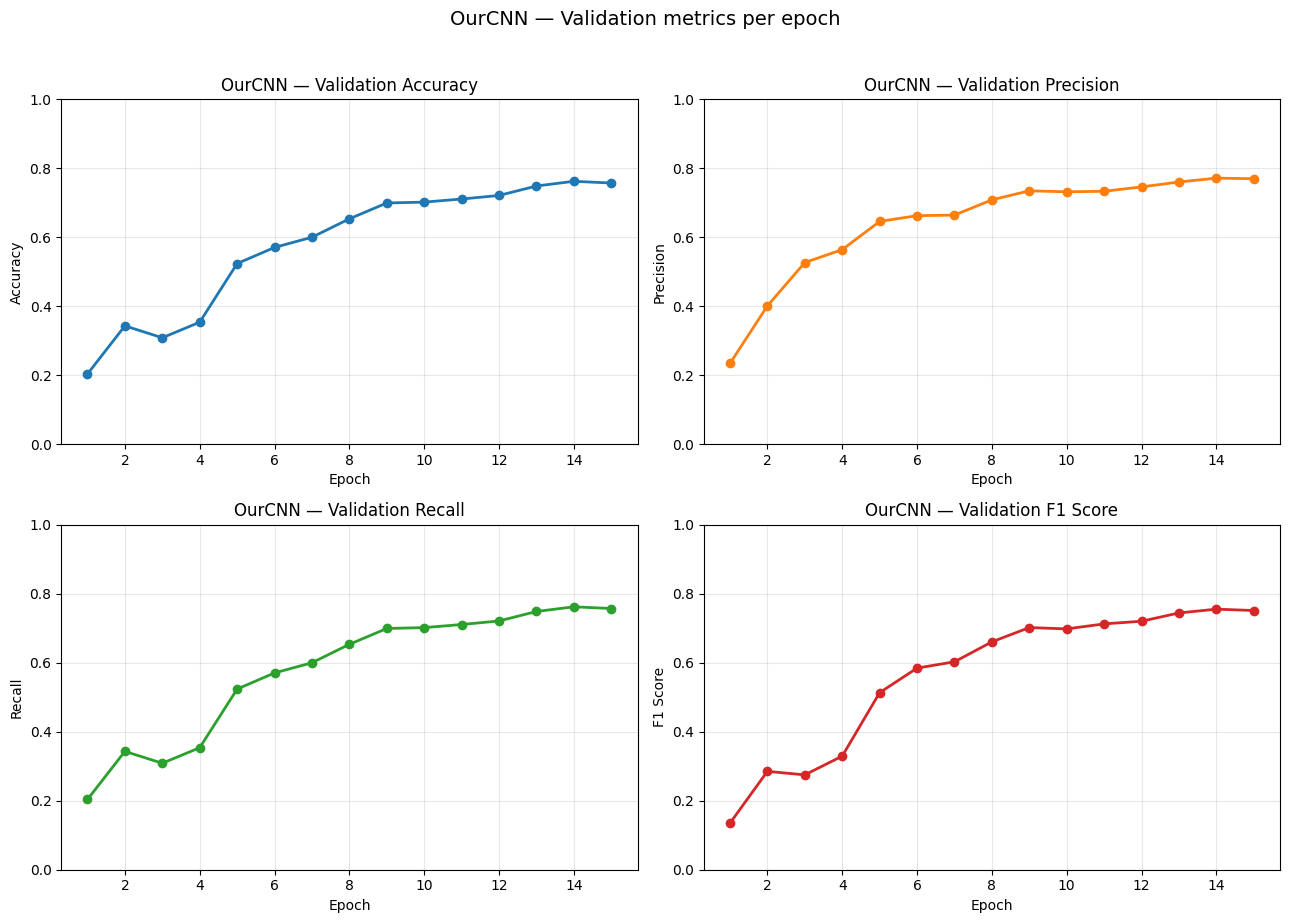

In [11]:
# 11) Per-epoch validation curves (accuracy, precision, recall, F1)
history = all_histories[MODEL_NAME]
epochs_axis = list(range(1, len(history["val_acc"]) + 1))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
metrics_plot = [
    ("val_acc", "Accuracy", axes[0][0], "tab:blue"),
    ("val_precision", "Precision", axes[0][1], "tab:orange"),
    ("val_recall", "Recall", axes[1][0], "tab:green"),
    ("val_f1", "F1 Score", axes[1][1], "tab:red"),
]
for key, label, ax, color in metrics_plot:
    ax.plot(epochs_axis, history[key], marker="o", color=color, linewidth=2)
    ax.set_title(f"{MODEL_NAME} — Validation {label}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

plt.suptitle(f"{MODEL_NAME} — Validation metrics per epoch", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(MODEL_DIR / "ourcnn_val_metrics_per_epoch.png", dpi=150, bbox_inches="tight")
plt.show()

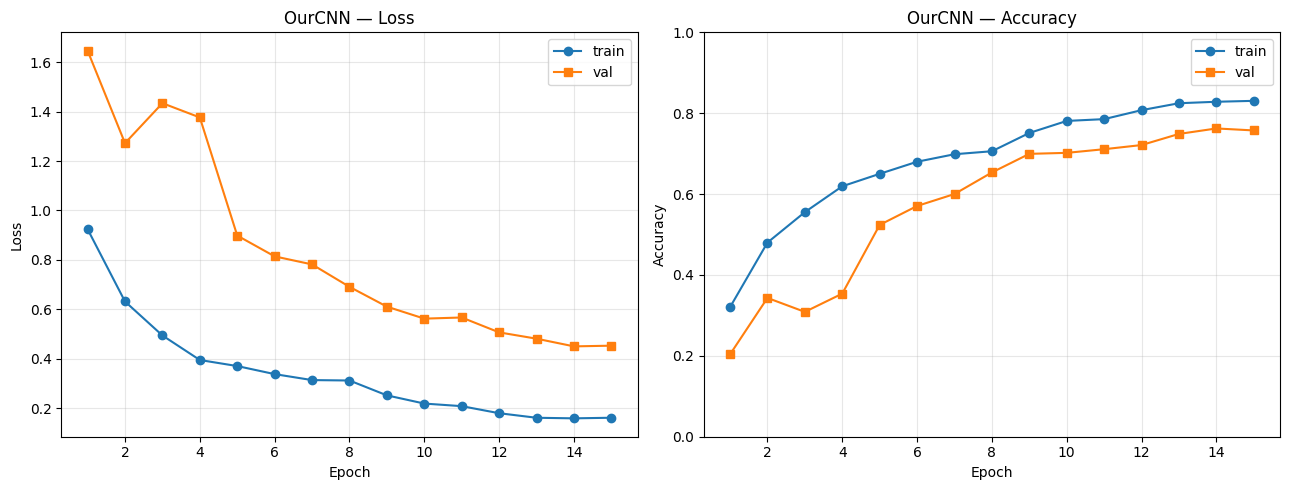

In [12]:
# 12) Train vs Val loss / accuracy
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_axis, history["train_loss"], label="train", marker="o")
axes[0].plot(epochs_axis, history["val_loss"], label="val", marker="s")
axes[0].set_title(f"{MODEL_NAME} — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, history["train_acc"], label="train", marker="o")
axes[1].plot(epochs_axis, history["val_acc"], label="val", marker="s")
axes[1].set_title(f"{MODEL_NAME} — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.savefig(MODEL_DIR / "ourcnn_train_val_curves.png", dpi=150, bbox_inches="tight")
plt.show()

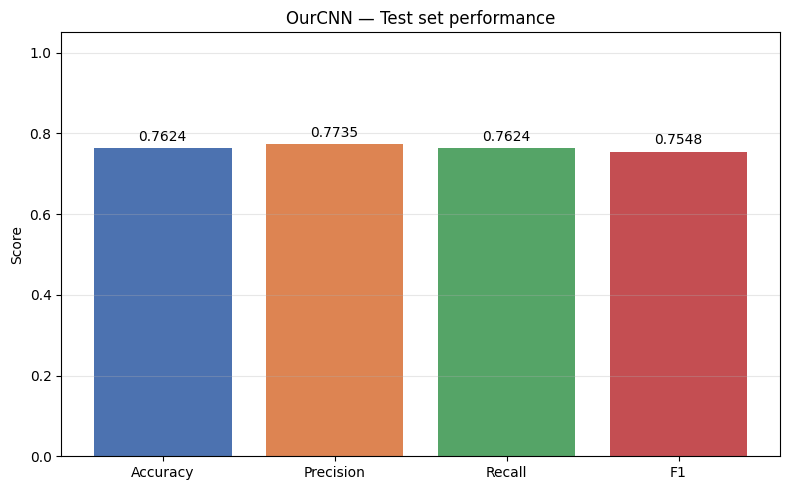

In [13]:
# 13) Final test-set performance bar chart (Accuracy, Precision, Recall, F1)
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
metric_values = [
    test_metrics["accuracy"],
    test_metrics["precision"],
    test_metrics["recall"],
    test_metrics["f1"],
]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(metric_names, metric_values, color=["#4C72B0", "#DD8452", "#55A467", "#C44E52"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"{MODEL_NAME} — Test set performance")
for bar, value in zip(bars, metric_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / "ourcnn_test_metrics_bar.png", dpi=150, bbox_inches="tight")
plt.show()

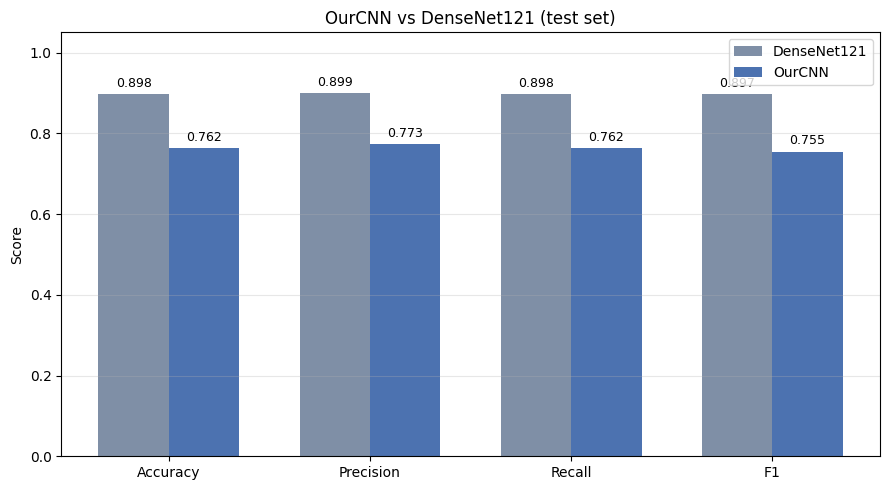

In [14]:
# 14) Comparison vs DenseNet121 (test set)
compare_metrics = ["Accuracy", "Precision", "Recall", "F1"]
ours_vals = [test_metrics["accuracy"], test_metrics["precision"], test_metrics["recall"], test_metrics["f1"]]
dense_vals = [
    DENSENET121_REF["Accuracy"],
    DENSENET121_REF["Precision"],
    DENSENET121_REF["Recall"],
    DENSENET121_REF["F1"],
]

x = np.arange(len(compare_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - width / 2, dense_vals, width, label="DenseNet121", color="#7F8FA6")
b2 = ax.bar(x + width / 2, ours_vals, width, label=MODEL_NAME, color="#4C72B0")
ax.set_ylim(0, 1.05)
ax.set_xticks(x)
ax.set_xticklabels(compare_metrics)
ax.set_ylabel("Score")
ax.set_title(f"{MODEL_NAME} vs DenseNet121 (test set)")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=9)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(MODEL_DIR / "ourcnn_vs_densenet121.png", dpi=150, bbox_inches="tight")
plt.show()

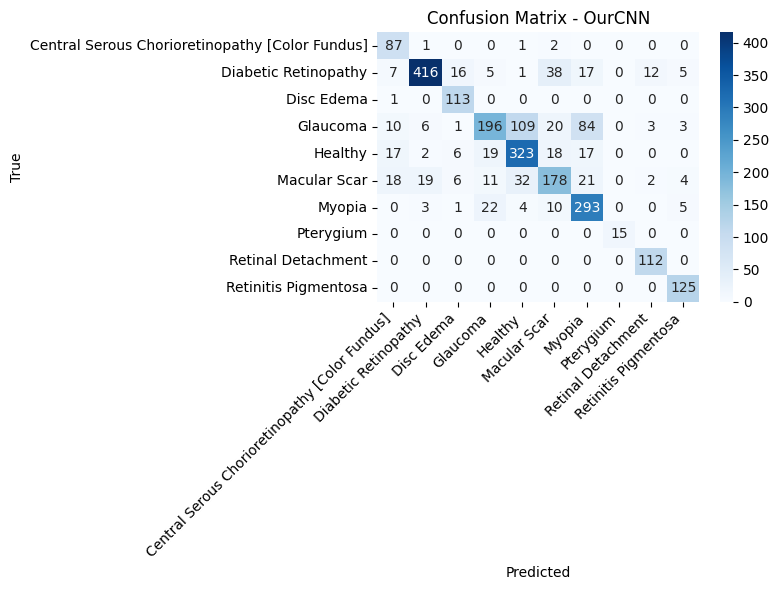

                                                 precision    recall  f1-score   support

Central Serous Chorioretinopathy [Color Fundus]     0.6214    0.9560    0.7532        91
                           Diabetic Retinopathy     0.9306    0.8046    0.8631       517
                                     Disc Edema     0.7902    0.9912    0.8794       114
                                       Glaucoma     0.7747    0.4537    0.5723       432
                                        Healthy     0.6872    0.8035    0.7408       402
                                   Macular Scar     0.6692    0.6117    0.6391       291
                                         Myopia     0.6782    0.8669    0.7610       338
                                      Pterygium     1.0000    1.0000    1.0000        15
                             Retinal Detachment     0.8682    1.0000    0.9295       112
                           Retinitis Pigmentosa     0.8803    1.0000    0.9363       125

                   

In [15]:
# 15) Confusion matrix and classification report
y_true, y_pred = all_confusions[MODEL_NAME]
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
)
plt.title(f"Confusion Matrix - {MODEL_NAME}")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(MODEL_DIR / "ourcnn_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

In [16]:
# 16) Final summary
print("=" * 60)
print(f"{MODEL_NAME} - Final summary")
print("=" * 60)
print(f"Parameters       : {int(results_df.iloc[0]['Params']):,}")
print(f"Test accuracy    : {test_metrics['accuracy']:.4f}")
print(f"Test precision   : {test_metrics['precision']:.4f}")
print(f"Test recall      : {test_metrics['recall']:.4f}")
print(f"Test F1          : {test_metrics['f1']:.4f}")
print(f"Training time    : {train_time / 60:.2f} min")
print("-" * 60)
print(f"DenseNet121 (ref): {DENSENET121_REF['Params']:,} params, F1={DENSENET121_REF['F1']:.4f}")
print(f"Param reduction  : {DENSENET121_REF['Params'] / int(results_df.iloc[0]['Params']):.1f}x smaller")
print("=" * 60)

OurCNN - Final summary
Parameters       : 122,972
Test accuracy    : 0.7624
Test precision   : 0.7735
Test recall      : 0.7624
Test F1          : 0.7548
Training time    : 112.22 min
------------------------------------------------------------
DenseNet121 (ref): 7,978,856 params, F1=0.8974
Param reduction  : 64.9x smaller


In [ ]:
# 11) WeightedRandomSampler setup (balance the training batches)
from pathlib import Path
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from collections import Counter

# Output folder for the WRS experiment (used by the next cell)
MODEL_DIR_WRS = Path(r"D:\CSE498 Research Updated\Custom CNN\OurCNN models\Models with WeightedRandomSampler")
MODEL_DIR_WRS.mkdir(parents=True, exist_ok=True)
print("Model output (WeightedRandomSampler run):", MODEL_DIR_WRS)

# Show what the current/original train_loader is doing
print("Existing train_loader sampler:", type(getattr(train_loader, "sampler", None)).__name__)

# Class distribution in the training split
label_counts_wrs = Counter(train_df["label"].tolist())
print("Train label counts (before sampling):")
for k in sorted(label_counts_wrs.keys()):
    print(f"  class {k}: {label_counts_wrs[k]}")

# Build per-sample weights (inverse frequency) and sampler
sample_weights_wrs = [1.0 / label_counts_wrs[int(lbl)] for lbl in train_df["label"].tolist()]
print(
    "Sample weight summary (min/mean/max):",
    f"{min(sample_weights_wrs):.6f}",
    f"{(sum(sample_weights_wrs)/len(sample_weights_wrs)):.6f}",
    f"{max(sample_weights_wrs):.6f}",
)

sampler_wrs = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights_wrs),
    num_samples=len(sample_weights_wrs),
    replacement=True,
)

# New train loader that uses WeightedRandomSampler
train_loader_wrs = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler_wrs,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print("WRS enabled -> train_loader_wrs created")
print("Batches/epoch:", len(train_loader_wrs), "| Batch size:", BATCH_SIZE)


Model output (WeightedRandomSampler run): D:\CSE498 Research Updated\Custom CNN\OurCNN models\Models with WeightedRandomSampler
Existing train_loader sampler: WeightedRandomSampler
Train label counts (before sampling):
  class 0: 424
  class 1: 2411
  class 2: 533
  class 3: 2016
  class 4: 1873
  class 5: 1356
  class 6: 1576
  class 7: 71
  class 8: 525
  class 9: 584
Sample weight summary (min/mean/max): 0.000415 0.000880 0.014085
WRS enabled -> train_loader_wrs created
Batches/epoch: 711 | Batch size: 16


OurCNN | ep 1/15:   2%|▌                            | 15/711 [00:14<07:00,  1.65it/s, loss=1.8934, acc=0.1167]

In [ ]:
# 12) Train + evaluate OurCNN using train_loader_wrs (WeightedRandomSampler)
import pandas as pd

# Temporarily redirect saving to the WRS folder
MODEL_DIR_ORIG = MODEL_DIR
MODEL_DIR = MODEL_DIR_WRS

model_wrs = OurCNN(num_classes=NUM_CLASSES)
_total_wrs, _trainable_wrs = count_parameters(model_wrs)
print(f"Trainable params before training (WRS run): {_trainable_wrs:,}")

best_model_wrs, hist_wrs, train_time_wrs, w_path_wrs, b_path_wrs = train_one_model(
    model_name=MODEL_NAME,
    model=model_wrs,
    train_dl=train_loader_wrs,
    val_dl=val_loader,
    image_size=IMG_SIZE,
    epochs=EPOCHS,
)

test_metrics_wrs = evaluate_model(best_model_wrs.to(device), test_loader)

wrs_result = {
    "Model": f"{MODEL_NAME} (WeightedRandomSampler)",
    "Params": _trainable_wrs,
    "Accuracy": test_metrics_wrs["accuracy"],
    "Precision": test_metrics_wrs["precision"],
    "Recall": test_metrics_wrs["recall"],
    "F1": test_metrics_wrs["f1"],
    "Training Time (s)": train_time_wrs,
    "Weights Path": w_path_wrs,
    "Bundle Path": b_path_wrs,
}

# Append and show performance like before (last two rows: original vs WRS)
try:
    all_results.append(wrs_result)
except Exception:
    all_results = [wrs_result]

display(pd.DataFrame(all_results).tail(2))

# Restore MODEL_DIR
MODEL_DIR = MODEL_DIR_ORIG
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Trainable params before training (WRS run): 122,972

===== Training OurCNN =====
[OurCNN] Epoch 1/15 — 711 batches (started 17:38:22)


OurCNN | ep 1/15: 100%|████████████████████████████| 711/711 [07:54<00:00,  1.50it/s, loss=0.9214, acc=0.3218]


Epoch 1/15 | train_loss=0.9214 train_acc=0.3218 | val_loss=1.7703 val_acc=0.1576 val_f1=0.0941
[OurCNN] Epoch 2/15 — 711 batches (started 17:47:44)


OurCNN | ep 2/15: 100%|████████████████████████████| 711/711 [07:16<00:00,  1.63it/s, loss=0.6523, acc=0.4685]


Epoch 2/15 | train_loss=0.6523 train_acc=0.4685 | val_loss=1.3904 val_acc=0.3530 val_f1=0.2983
[OurCNN] Epoch 3/15 — 711 batches (started 17:56:16)


...

OurCNN | ep 14/15: 100%|███████████████████████████| 711/711 [06:23<00:00,  1.85it/s, loss=0.1696, acc=0.8214]


Epoch 14/15 | train_loss=0.1696 train_acc=0.8214 | val_loss=0.4661 val_acc=0.7549 val_f1=0.7498
[OurCNN] Epoch 15/15 — 711 batches (started 20:46:11)


OurCNN | ep 15/15: 100%|███████████████████████████| 711/711 [08:30<00:00,  1.39it/s, loss=0.1732, acc=0.8199]


Epoch 15/15 | train_loss=0.1732 train_acc=0.8199 | val_loss=0.4645 val_acc=0.7541 val_f1=0.7484
Saved: D:\CSE498 Research Updated\Custom CNN\OurCNN models\Models with WeightedRandomSampler\ourcnn_best.pth
Saved bundle: D:\CSE498 Research Updated\Custom CNN\OurCNN models\Models with WeightedRandomSampler\ourcnn_bundle.pth


,Model,Params,Accuracy,Precision,Recall,F1,Training Time (s),Weights Path,Bundle Path
0,OurCNN (WeightedRandomSampler),122972,0.756668,0.767082,0.756668,0.751978,11874.37166,D:\CSE498 Research Updated\Custom CNN\OurCNN m...,D:\CSE498 Research Updated\Custom CNN\OurCNN m...
